SETUP

In [29]:
pip install tensorflow[and-cuda] opencv-python matplotlib

Note: you may need to restart the kernel to use updated packages.


In [30]:
pip list

Package                  Version
------------------------ -----------
absl-py                  2.4.0
asttokens                3.0.1
astunparse               1.6.3
certifi                  2026.2.25
charset-normalizer       3.4.4
comm                     0.2.3
contourpy                1.3.2
cycler                   0.12.1
debugpy                  1.8.20
decorator                5.2.1
exceptiongroup           1.3.1
executing                2.2.1
flatbuffers              25.12.19
fonttools                4.61.1
gast                     0.7.0
google-pasta             0.2.0
grpcio                   1.78.0
h5py                     3.15.1
idna                     3.11
ipykernel                7.2.0
ipython                  8.38.0
jedi                     0.19.2
jupyter_client           8.8.0
jupyter_core             5.9.1
keras                    3.12.1
kiwisolver               1.4.9
libclang                 18.1.1
Markdown                 3.10.2
markdown-it-py           4.0.0
MarkupSafe     

In [5]:
import tensorflow as tf
import os 

BATCH_SIZE = 16
SEED =  1

In [6]:
gpus = tf.config.experimental.list_physical_devices('GPU')

In [7]:
gpus

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [8]:
#avoid oom error
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

In [9]:
from tensorflow.keras.applications import EfficientNetV2L

model = EfficientNetV2L(weights = 'imagenet', include_top=False, input_shape=(224,224,3))

I0000 00:00:1772573760.908194   49226 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5563 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [10]:
#model.summary()

In [11]:
for layer in model.layers:
    layer.trainable = False

In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *

my_model = Sequential([model,
                        Conv2D(256, 3, 1, 
                        activation = 'relu'),
                        GlobalAveragePooling2D(), 
                        Dense(256, activation = 'relu'),
                        Dropout(0.2),
                        Dense(256, activation = 'relu'),
                        Dropout(0.2), 
                        Dense(525, activation = 'softmax')])
my_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetv2-l (Functional)   │ (None, 7, 7, 1280)     │   117,746,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 5, 5, 256)      │     2,949,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 525)            │       134,925 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,962,733 (461.44 MB)

 Trainable params: 3,215,885 (12.27 MB)

 Non-trainable params: 117,746,848 (449.17 MB)

In [13]:
data = tf.keras.utils.image_dataset_from_directory('data/BirdData', color_mode = 'rgb', batch_size = BATCH_SIZE, image_size = (224,224), shuffle = True, validation_split = 0.2, subset = 'training', seed = SEED)
Valdata = tf.keras.utils.image_dataset_from_directory('data/ValData', color_mode = 'rgb', batch_size = BATCH_SIZE, image_size = (224,224), shuffle = True, validation_split = 0.2, subset = 'validation', seed = SEED)
Testdata = tf.keras.utils.image_dataset_from_directory('data/TestData', color_mode = 'rgb', batch_size = BATCH_SIZE, image_size = (224,224), shuffle = False, seed = SEED)

Found 84635 files belonging to 525 classes.
Using 67708 files for training.
Found 2625 files belonging to 525 classes.
Using 525 files for validation.
Found 2625 files belonging to 525 classes.


In [14]:
interator =  iter(data)
next(interator)[0][0].numpy().shape

(224, 224, 3)

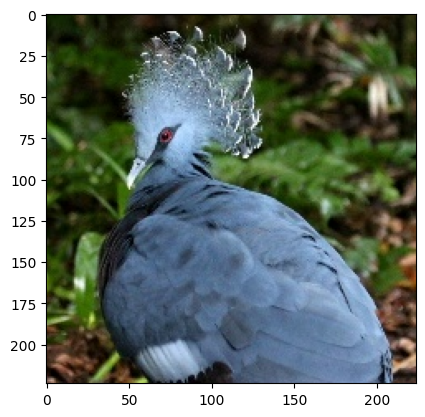

In [15]:
import matplotlib.pyplot as plt
import numpy as np

plt.imshow(next(interator)[0][0].numpy().astype(np.int32))

In [16]:
from tensorflow.image import flip_left_right, adjust_brightness, adjust_contrast

def augment(image, label):
    image = flip_left_right(image)
    image = adjust_brightness(image, delta = 0.1)
    image = adjust_contrast(image, contrast_factor = 1.75)

    return (image, label)

data = data.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

interator = iter(data)

In [ ]:
from tensorflow.keras.applications.efficientnet_v2 import preprocess_input

def preprocess(image, label):
    image = preprocess_input(image)
    return image, label

data = data.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
Valdata = Valdata.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-99..371].


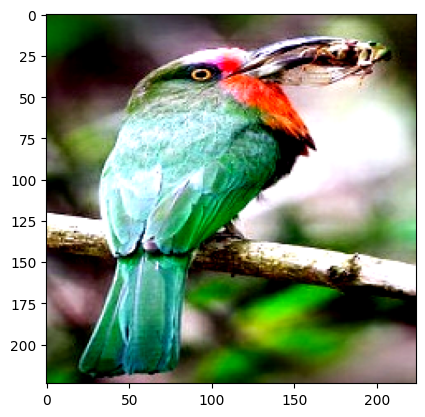

In [17]:
plt.imshow(next(interator)[0][0].numpy().astype(np.int32))

In [18]:
data = data.prefetch(tf.data.AUTOTUNE)
data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [19]:
Valdata = Valdata.prefetch(tf.data.AUTOTUNE)
Valdata

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [20]:
from tensorflow.keras.metrics import *

from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import SparseCategoricalCrossentropy

metrics = [
    'accuracy',
    #Precision(class_id=None, average='macro'),
    #Recall(class_id=None, average='macro'),
    AUC(multi_label=True)
]

my_model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    optimizer=tf.keras.optimizers.Adam(1e-3),
    metrics=['accuracy']
)

In [21]:
from tensorflow.keras.callbacks import EarlyStopping

es = EarlyStopping(patience=25, monitor='val_loss')

In [47]:
hist = my_model.fit(data, epochs = 25, validation_data = Valdata, callbacks = [es])

Epoch 1/25


2026-03-03 12:05:46.558012: I external/local_xla/xla/service/service.cc:163] XLA service 0x717638004f20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-03-03 12:05:46.558072: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9
2026-03-03 12:05:49.003412: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-03-03 12:05:59.260353: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900
2026-03-03 12:06:13.841095: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:06:14.140536: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel 

4231/4232 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - accuracy: 0.1533 - loss: 4.2022

2026-03-03 12:14:15.070803: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:14:15.316567: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:14:16.304430: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:14:16.583514: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:14:17.645393: E external/local_xla/xla/stream_

4232/4232 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.1533 - loss: 4.2020

2026-03-03 12:15:17.741883: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:15:17.969316: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:15:18.970164: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:15:19.238833: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-03-03 12:15:19.523192: E external/local_xla/xla/stream_

4232/4232 ━━━━━━━━━━━━━━━━━━━━ 622s 117ms/step - accuracy: 0.2477 - loss: 3.3091 - val_accuracy: 0.5086 - val_loss: 1.7281
Epoch 2/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 381s 90ms/step - accuracy: 0.4593 - loss: 2.0566 - val_accuracy: 0.6343 - val_loss: 1.2057
Epoch 3/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 378s 89ms/step - accuracy: 0.5465 - loss: 1.7018 - val_accuracy: 0.6552 - val_loss: 1.1491
Epoch 4/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 377s 89ms/step - accuracy: 0.5910 - loss: 1.5268 - val_accuracy: 0.7257 - val_loss: 0.9622
Epoch 5/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 380s 90ms/step - accuracy: 0.6196 - loss: 1.4339 - val_accuracy: 0.7276 - val_loss: 0.9410
Epoch 6/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 378s 89ms/step - accuracy: 0.6376 - loss: 1.3705 - val_accuracy: 0.7448 - val_loss: 0.9073
Epoch 7/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 380s 90ms/step - accuracy: 0.6548 - loss: 1.3265 - val_accuracy: 0.7410 - val_loss: 0.8936
Epoch 8/25
4232/4232 ━━━━━━━━━━━━━━━━━━━━ 379s 90ms/step - accuracy: 0.6691 - l

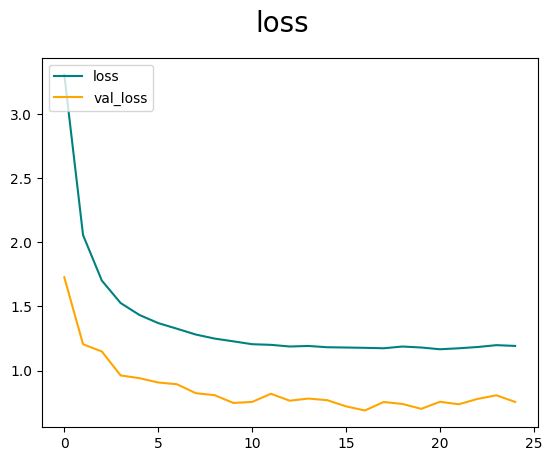

In [48]:
fig = plt.figure()
plt.plot(hist.history['loss'], color = 'teal', label = 'loss')
plt.plot(hist.history['val_loss'], color = 'orange', label = 'val_loss')
fig.suptitle('loss', fontsize=20)
plt.legend(loc = "upper left")
plt.show()

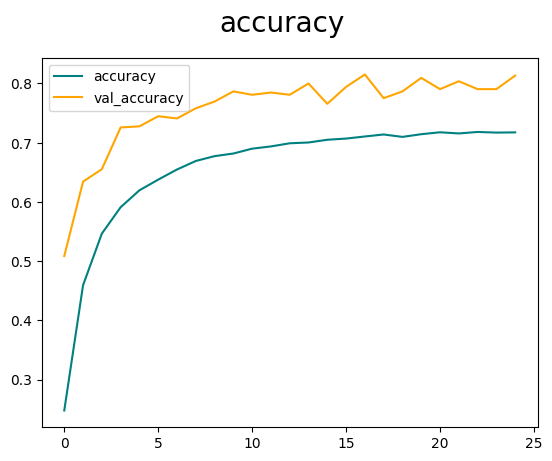

In [49]:
fig = plt.figure()
plt.plot(hist.history['accuracy'], color = 'teal', label = 'accuracy')
plt.plot(hist.history['val_accuracy'], color = 'orange', label = 'val_accuracy')
fig.suptitle('accuracy', fontsize=20)
plt.legend(loc = "upper left")
plt.show()

In [22]:
from tensorflow.keras.models import load_model

In [ ]:
my_model.save(os.path.join('models', 'BirdAI-v6-81%.keras'))

In [23]:
my_model = load_model(os.path.join('models', 'BirdAI-v6-81%.keras'))

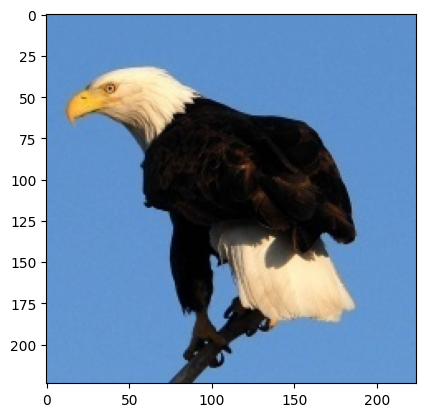

In [25]:
import cv2
import imghdr

img = cv2.imread('Bald Eagle.jpg')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

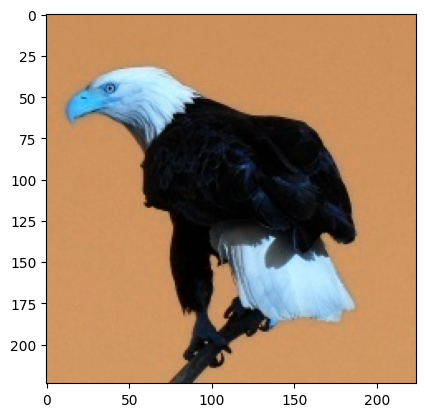

In [32]:
#resized to 256 256 for model
resize = tf.image.resize(img, (224,224))
plt.imshow(resize.numpy().astype(int))
plt.show

In [33]:
#tests with the model
yhat = my_model.predict(np.expand_dims(resize, 0))
yhat

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step


array([[[[ 7.92821121e+00,  5.05301952e+00,  3.72875428e+00, ...,
           2.25575256e+00,  2.37492251e+00,  1.13264263e+00],
         [-7.48167560e-02,  4.26121742e-01,  3.38435590e-01, ...,
          -2.53552735e-01, -2.75539488e-01,  4.22524242e-03],
         [-1.91918910e-01,  5.27291179e-01,  3.27665478e-01, ...,
          -2.65997916e-01, -2.58454889e-01, -2.35677645e-01],
         ...,
         [-2.77786165e-01,  3.40168744e-01, -1.21581234e-01, ...,
          -2.57189453e-01, -2.75699466e-01, -2.75519460e-01],
         [-2.78343707e-01, -2.67807752e-01, -2.14175597e-01, ...,
          -1.99831024e-01, -2.78363436e-01, -1.35350227e-01],
         [-2.64936507e-01, -2.48087034e-01, -2.20996246e-01, ...,
          -2.77261287e-01, -2.54005730e-01, -1.93974301e-01]],

        [[ 6.84766471e-01, -2.19373882e-01,  2.66004473e-01, ...,
          -9.51966271e-02, -2.49230146e-01, -1.77936003e-01],
         [ 3.09745610e-01,  6.60133660e-01,  1.46237326e+00, ...,
          -4.29341607e

In [34]:
max_idx = np.argmax(yhat)
max_idx

np.int64(1116)

In [ ]:
data_dir = 'data/BirdData'
birdnames = []
for image_class in os.listdir(data_dir):
    birdnames.append(image_class)
birdnames = sorted(os.listdir(data_dir))
print(birdnames[max_idx])

BLUE DACNIS


In [61]:
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import load_model

es = EarlyStopping(patience=25, monitor='val_loss', restore_best_weights= True)

In [23]:
my_model = load_model(os.path.join('models', 'BirdAI-v4.h5'))

In [ ]:
from tensorflow.keras.optimizers import Adam
my_model.compile(optimizer=Adam(learning_rate=1e-4), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [25]:
hist = my_model.fit(data, epochs = 20, validation_data = Valdata, callbacks = [es])

Epoch 1/20


ValueError: Arguments `target` and `output` must have the same rank (ndim). Received: target.shape=(None,), output.shape=(None, 7, 7, 1280)